## Lab 9: Decision Trees and Ensemble Learning

**Reproducibility:** all data splits and stochastic models use `random_state=42` where applicable.  
This notebook follows the assignment tasks: classification, regression/pruning, and ensemble learning.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import (
    DecisionTreeClassifier, DecisionTreeRegressor,
    plot_tree, export_text
)
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
)
from sklearn.metrics import accuracy_score, mean_squared_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

print("Libraries imported. Random state =", RANDOM_STATE)

Libraries imported. Random state = 42


## Task 1  Decision Tree Classification

Load the Digits dataset and create stratified 60% / 20% / 20% train, validation, and test sets.

In [2]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

X_temp, X_test, y_temp, y_test = train_test_split(
    X_digits, y_digits, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y_digits
)
# 0.25 of the remaining 80% gives 20% of the full dataset for validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=RANDOM_STATE,
    stratify=y_temp
)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Percentage": [100*len(y_train)/len(y_digits),
                   100*len(y_val)/len(y_digits),
                   100*len(y_test)/len(y_digits)]
})
display(split_summary)
print("Feature count:", X_digits.shape[1], "| Classes:", np.unique(y_digits))

,Split,Samples,Percentage
0,Train,1077,59.933222
1,Validation,360,20.033389
2,Test,360,20.033389


Feature count: 64 | Classes: [0 1 2 3 4 5 6 7 8 9]


### Task 1A Impurity and Information Gain

Implement entropy and Gini impurity from scratch. For entropy, zero-probability classes contribute zero.

In [3]:
def entropy_impurity(y):
    """Shannon entropy H(S) in bits, implemented from scratch."""
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    probabilities = probabilities[probabilities > 0]
    return float(-np.sum(probabilities * np.log2(probabilities)))

def gini_impurity(y):
    """Gini impurity G(S) = sum_c p_c (1 - p_c), implemented from scratch."""
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return float(np.sum(probabilities * (1 - probabilities)))

# Small sanity check
example_labels = np.array([0, 0, 1, 1])
print("Example entropy:", entropy_impurity(example_labels), "(expected 1.0)")
print("Example Gini:", gini_impurity(example_labels), "(expected 0.5)")

Example entropy: 1.0 (expected 1.0)
Example Gini: 0.5 (expected 0.5)


In [4]:
entropy_tree = DecisionTreeClassifier(
    criterion="entropy", max_depth=4, random_state=RANDOM_STATE
)
gini_tree_d4 = DecisionTreeClassifier(
    criterion="gini", max_depth=4, random_state=RANDOM_STATE
)
entropy_tree.fit(X_train, y_train)
gini_tree_d4.fit(X_train, y_train)

impurity_comparison = pd.DataFrame([
    {
        "Criterion": "Entropy",
        "Train accuracy": accuracy_score(y_train, entropy_tree.predict(X_train)),
        "Validation accuracy": accuracy_score(y_val, entropy_tree.predict(X_val)),
        "Actual depth": entropy_tree.get_depth(),
        "Leaf nodes": entropy_tree.get_n_leaves()
    },
    {
        "Criterion": "Gini",
        "Train accuracy": accuracy_score(y_train, gini_tree_d4.predict(X_train)),
        "Validation accuracy": accuracy_score(y_val, gini_tree_d4.predict(X_val)),
        "Actual depth": gini_tree_d4.get_depth(),
        "Leaf nodes": gini_tree_d4.get_n_leaves()
    }
])
display(impurity_comparison.style.format({
    "Train accuracy": "{:.4f}", "Validation accuracy": "{:.4f}"
}))

,Criterion,Train accuracy,Validation accuracy,Actual depth,Leaf nodes
0,Entropy,0.6825,0.6500,4,16
1,Gini,0.5952,0.5583,4,13


In [5]:
# Root split and information gain for the entropy tree.
root_feature_index = int(entropy_tree.tree_.feature[0])
root_threshold = float(entropy_tree.tree_.threshold[0])
left_mask = X_train[:, root_feature_index] <= root_threshold
right_mask = ~left_mask

root_entropy = entropy_impurity(y_train)
left_entropy = entropy_impurity(y_train[left_mask])
right_entropy = entropy_impurity(y_train[right_mask])
weighted_child_entropy = (
    left_mask.sum()/len(y_train) * left_entropy
    + right_mask.sum()/len(y_train) * right_entropy
)
root_information_gain = root_entropy - weighted_child_entropy

print("Root feature index:", root_feature_index)
print("Root feature name:", f"pixel_{root_feature_index}")
print("Root split threshold:", root_threshold)
print("Parent entropy:", root_entropy)
print("Left-child entropy:", left_entropy, "| samples:", int(left_mask.sum()))
print("Right-child entropy:", right_entropy, "| samples:", int(right_mask.sum()))
print("Root information gain:", root_information_gain)

Root feature index: 33
Root feature name: pixel_33
Root split threshold: 2.5
Parent entropy: 3.321764891835482
Left-child entropy: 3.0518113732292615 | samples: 719
Right-child entropy: 2.483972296079777 | samples: 358
Root information gain: 0.4587059695064202


### Task 1B Effect of Tree Depth

Train Gini trees with `max_depth` in `{2, 4, 8, None}`. Select the best model using validation accuracy only, then evaluate that selected model on the held-out test set.

In [6]:
depth_options = [2, 4, 8, None]
depth_models = {}
depth_rows = []

for depth in depth_options:
    model = DecisionTreeClassifier(
        criterion="gini", max_depth=depth, random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)
    depth_models[depth] = model
    depth_rows.append({
        "Requested max_depth": str(depth),
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Validation accuracy": accuracy_score(y_val, model.predict(X_val)),
        "Actual depth": model.get_depth(),
        "Leaf nodes": model.get_n_leaves()
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results.style.format({
    "Train accuracy": "{:.4f}", "Validation accuracy": "{:.4f}"
}))
best_depth_label = depth_results.loc[depth_results["Validation accuracy"].idxmax(), "Requested max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
best_classifier = depth_models[best_depth]
best_classifier_test_accuracy = accuracy_score(y_test, best_classifier.predict(X_test))
print(f"Selected max_depth={best_depth} by validation accuracy.")
print(f"Selected tree test accuracy: {best_classifier_test_accuracy:.4f}")

,Requested max_depth,Train accuracy,Validation accuracy,Actual depth,Leaf nodes
0,2,0.3240,0.3139,2,4
1,4,0.5952,0.5583,4,13
2,8,0.9517,0.8389,8,69
3,None,1.0000,0.8333,11,109


Selected max_depth=8 by validation accuracy.
Selected tree test accuracy: 0.8278


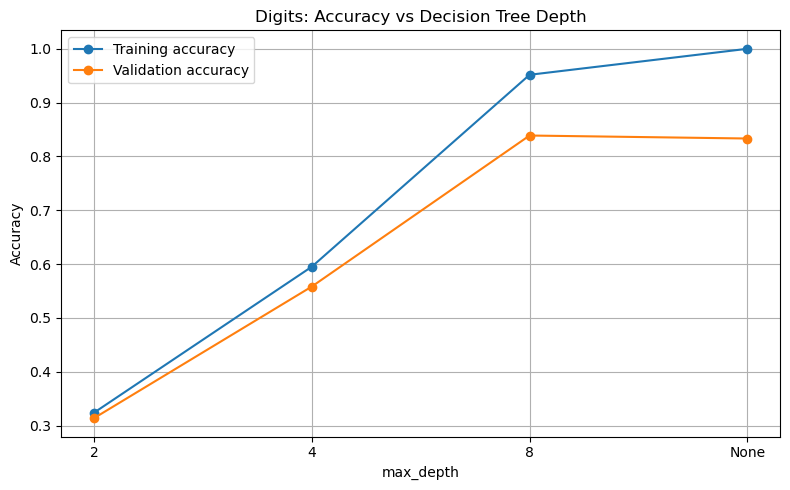

In [7]:
# Accuracy vs requested depth; None is displayed as "None" because it is unrestricted.
depth_labels = [str(d) for d in depth_options]
x = np.arange(len(depth_labels))
plt.plot(x, depth_results["Train accuracy"], marker="o", label="Training accuracy")
plt.plot(x, depth_results["Validation accuracy"], marker="o", label="Validation accuracy")
plt.xticks(x, depth_labels)
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Digits: Accuracy vs Decision Tree Depth")
plt.legend()
plt.tight_layout()
plt.show()

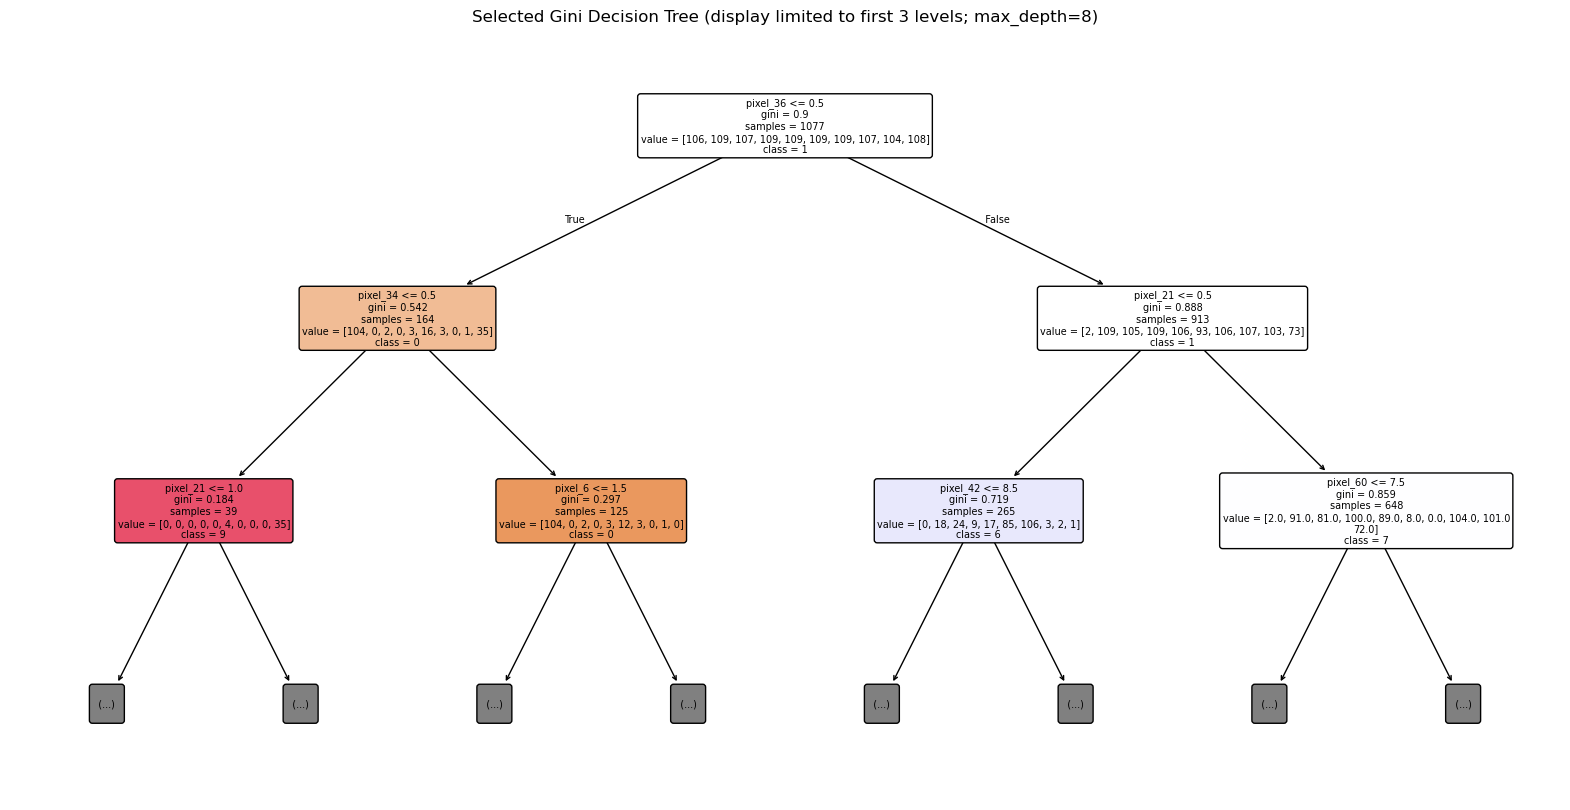

In [8]:
# Visualize the first three levels (root plus two levels below it).
plt.figure(figsize=(20, 10))
plot_tree(
    best_classifier, max_depth=2, feature_names=[f"pixel_{i}" for i in range(X_digits.shape[1])],
    class_names=[str(c) for c in digits.target_names], filled=True,
    rounded=True, fontsize=7
)
plt.title(f"Selected Gini Decision Tree (display limited to first 3 levels; max_depth={best_depth})")
plt.show()

In [11]:
# Data-grounded observations for Task 1
train_acc_depth = depth_results["Train accuracy"].to_numpy()
val_acc_depth = depth_results["Validation accuracy"].to_numpy()
print("Observations:")
print("- Entropy and Gini both choose splits that reduce node impurity, but their impurity formulas differ.")
print(f"- Across the tested depths, training accuracy ranges from {train_acc_depth.min():.3f} to {train_acc_depth.max():.3f}.")
print(f"- Validation accuracy ranges from {val_acc_depth.min():.3f} to {val_acc_depth.max():.3f}.")
print("- A widening train–validation accuracy gap at greater depth is evidence consistent with overfitting.")
print("- Best validation depth:", best_depth, "| test accuracy:", round(best_classifier_test_accuracy, 4))
display(depth_results.assign(
    Train_minus_validation=depth_results["Train accuracy"]-depth_results["Validation accuracy"]
).style.format({
    "Train accuracy": "{:.4f}", "Validation accuracy": "{:.4f}",
    "Train_minus_validation": "{:.4f}"
}))

Observations:
- Entropy and Gini both choose splits that reduce node impurity, but their impurity formulas differ.
- Across the tested depths, training accuracy ranges from 0.324 to 1.000.
- Validation accuracy ranges from 0.314 to 0.839.
- A widening train–validation accuracy gap at greater depth is evidence consistent with overfitting.
- Best validation depth: 8 | test accuracy: 0.8278


,Requested max_depth,Train accuracy,Validation accuracy,Actual depth,Leaf nodes,Train_minus_validation
0,2,0.3240,0.3139,2,4,0.0102
1,4,0.5952,0.5583,4,13,0.0368
2,8,0.9517,0.8389,8,69,0.1128
3,None,1.0000,0.8333,11,109,0.1667


## Task 2 Regression Trees and Pruning

Load Diabetes and create 60% / 20% / 20% train, validation, and test sets. The dataset is small, so results can vary with the split; the fixed seed makes this run reproducible.

In [14]:
diabetes = load_diabetes()
X_diabetes = diabetes.data
y_diabetes = diabetes.target

Xd_temp, Xd_test, yd_temp, yd_test = train_test_split(
    X_diabetes, y_diabetes, test_size=0.20, random_state=RANDOM_STATE
)
Xd_train, Xd_val, yd_train, yd_val = train_test_split(
    Xd_temp, yd_temp, test_size=0.25, random_state=RANDOM_STATE
)

display(pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(yd_train), len(yd_val), len(yd_test)],
    "Percentage": [100*len(yd_train)/len(y_diabetes),
                   100*len(yd_val)/len(y_diabetes),
                   100*len(yd_test)/len(y_diabetes)]
}))
print("Feature count:", X_diabetes.shape[1])

,Split,Samples,Percentage
0,Train,264,59.728507
1,Validation,89,20.135747
2,Test,89,20.135747


Feature count: 10


### Task 2A Regression Tree

Fit trees with depths `{2, 4, 8, None}` and compare training and validation RMSE. Lower RMSE is better.

In [15]:
reg_depth_options = [2, 4, 8, None]
reg_models = {}
reg_rows = []

for depth in reg_depth_options:
    model = DecisionTreeRegressor(
        max_depth=depth, random_state=RANDOM_STATE
    )
    model.fit(Xd_train, yd_train)
    reg_models[depth] = model
    reg_rows.append({
        "Requested max_depth": str(depth),
        "Train RMSE": rmse(yd_train, model.predict(Xd_train)),
        "Validation RMSE": rmse(yd_val, model.predict(Xd_val)),
        "Actual depth": model.get_depth(),
        "Leaf nodes": model.get_n_leaves()
    })

reg_depth_results = pd.DataFrame(reg_rows)
display(reg_depth_results.style.format({
    "Train RMSE": "{:.3f}", "Validation RMSE": "{:.3f}"
}))
best_reg_label = reg_depth_results.loc[reg_depth_results["Validation RMSE"].idxmin(), "Requested max_depth"]
best_reg_depth = None if best_reg_label == "None" else int(best_reg_label)
best_reg_tree = reg_models[best_reg_depth]
print("Selected depth by lowest validation RMSE:", best_reg_depth)
print("Selected depth tree test RMSE:", f"{rmse(yd_test, best_reg_tree.predict(Xd_test)):.3f}")

,Requested max_depth,Train RMSE,Validation RMSE,Actual depth,Leaf nodes
0,2,57.627,58.781,2,4
1,4,49.765,59.761,4,15
2,8,26.000,64.663,8,93
3,None,0.000,65.809,15,259


Selected depth by lowest validation RMSE: 2
Selected depth tree test RMSE: 61.100


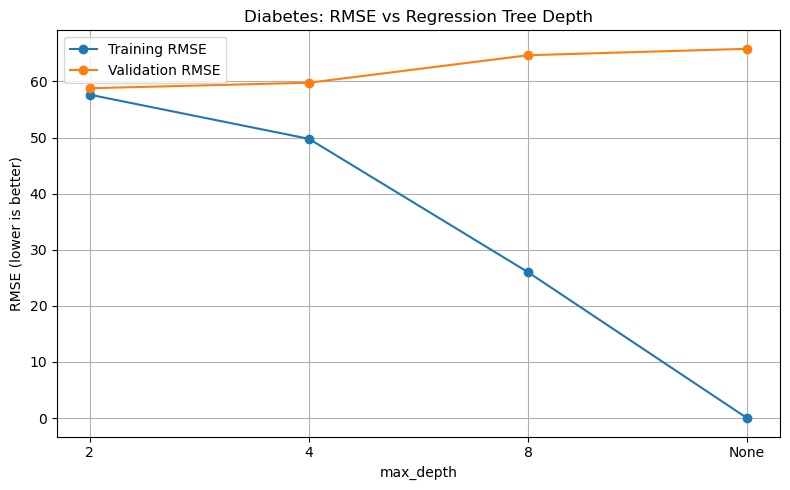

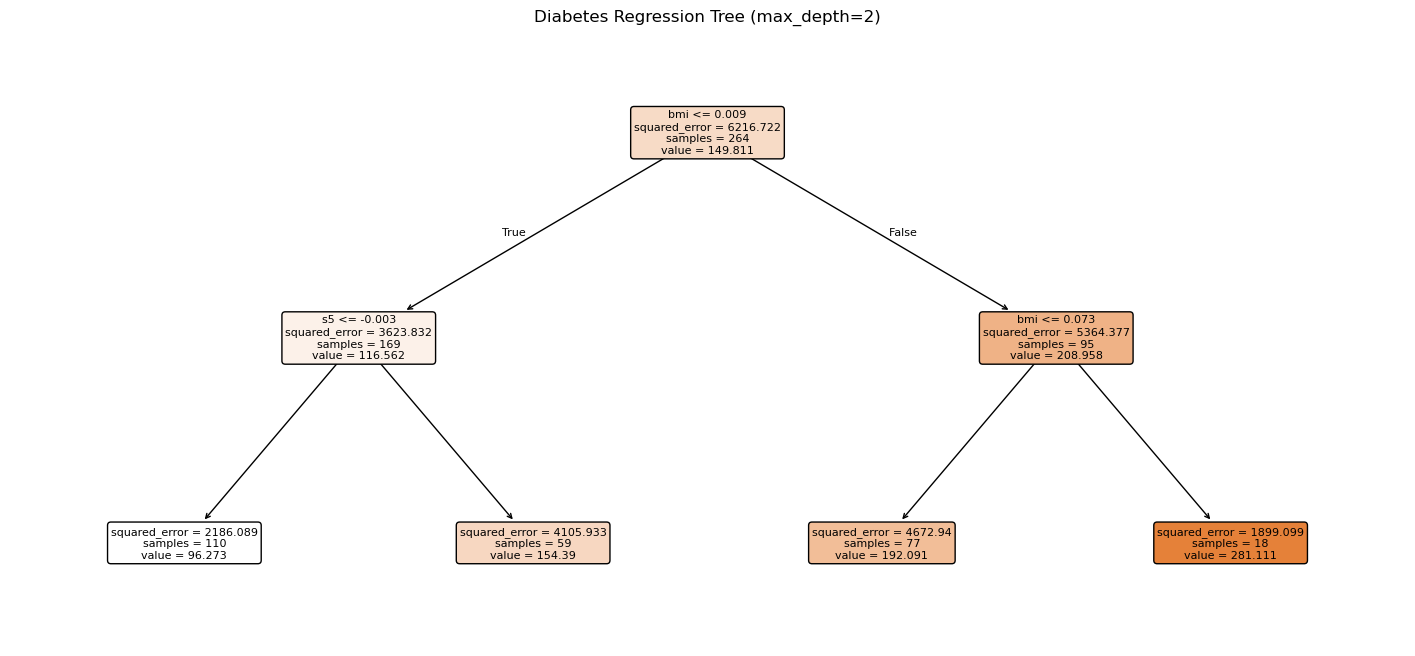

In [16]:
depth_plot_labels = [str(d) for d in reg_depth_options]
x = np.arange(len(depth_plot_labels))
plt.plot(x, reg_depth_results["Train RMSE"], marker="o", label="Training RMSE")
plt.plot(x, reg_depth_results["Validation RMSE"], marker="o", label="Validation RMSE")
plt.xticks(x, depth_plot_labels)
plt.xlabel("max_depth")
plt.ylabel("RMSE (lower is better)")
plt.title("Diabetes: RMSE vs Regression Tree Depth")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(18, 8))
plot_tree(
    reg_models[2], max_depth=2, feature_names=diabetes.feature_names,
    filled=True, rounded=True, fontsize=8
)
plt.title("Diabetes Regression Tree (max_depth=2)")
plt.show()

### Task 2B Cost-Complexity Pruning

Get candidate `ccp_alpha` values from an unrestricted tree's pruning path. Evaluate each candidate on validation RMSE and compare the unrestricted, validation-selected depth tree, and best pruned tree on test RMSE and leaf count.

In [17]:
unrestricted_reg_tree = DecisionTreeRegressor(random_state=RANDOM_STATE)
unrestricted_reg_tree.fit(Xd_train, yd_train)
pruning_path = unrestricted_reg_tree.cost_complexity_pruning_path(Xd_train, yd_train)
alphas = np.unique(pruning_path.ccp_alphas)

# Fit every alpha returned by the path. The largest alpha generally produces a stump.
pruned_models = {}
pruning_rows = []
for alpha in alphas:
    model = DecisionTreeRegressor(
        random_state=RANDOM_STATE, ccp_alpha=float(alpha)
    )
    model.fit(Xd_train, yd_train)
    pruned_models[float(alpha)] = model
    pruning_rows.append({
        "ccp_alpha": float(alpha),
        "Validation RMSE": rmse(yd_val, model.predict(Xd_val)),
        "Leaf nodes": model.get_n_leaves(),
        "Actual depth": model.get_depth()
    })

pruning_results = pd.DataFrame(pruning_rows).sort_values("ccp_alpha").reset_index(drop=True)
display(pruning_results.head(10).style.format({
    "ccp_alpha": "{:.6g}", "Validation RMSE": "{:.3f}"
}))
print("Number of candidate alpha values:", len(alphas))

,ccp_alpha,Validation RMSE,Leaf nodes,Actual depth
0,0,65.809,259,15
1,0.00189394,65.792,251,15
2,0.00252525,65.792,250,15
3,0.00505051,65.792,249,15
4,0.00757576,65.820,243,15
5,0.010101,65.821,242,15
6,0.0157828,65.821,241,15
7,0.0170455,65.808,236,15
8,0.030303,65.848,229,15
9,0.040404,65.847,228,15


Number of candidate alpha values: 182


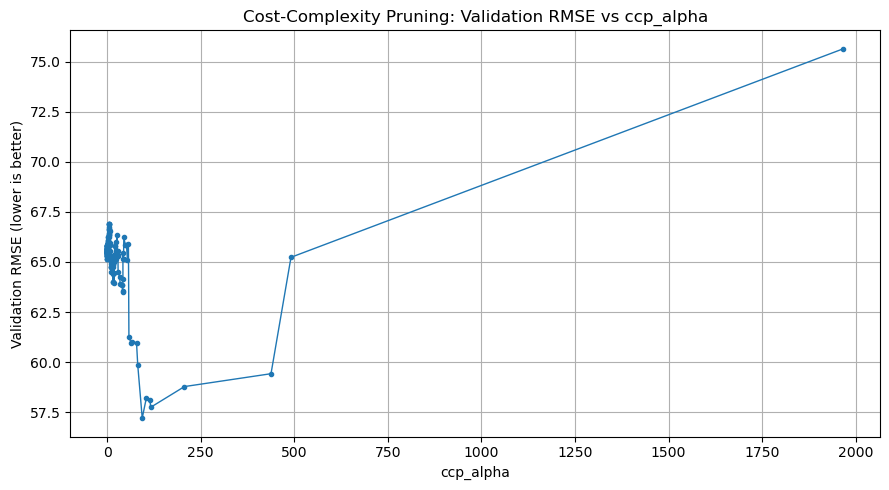

Selected ccp_alpha: 93.89693431394915
Selected pruned tree validation RMSE: 57.207


In [18]:
plt.figure(figsize=(9, 5))
plt.plot(pruning_results["ccp_alpha"], pruning_results["Validation RMSE"], marker=".", linewidth=1)
plt.xlabel("ccp_alpha")
plt.ylabel("Validation RMSE (lower is better)")
plt.title("Cost-Complexity Pruning: Validation RMSE vs ccp_alpha")
plt.tight_layout()
plt.show()

best_alpha = float(pruning_results.loc[pruning_results["Validation RMSE"].idxmin(), "ccp_alpha"])
best_pruned_tree = pruned_models[best_alpha]
print("Selected ccp_alpha:", best_alpha)
print("Selected pruned tree validation RMSE:", f"{rmse(yd_val, best_pruned_tree.predict(Xd_val)):.3f}")

In [19]:
regression_comparison = pd.DataFrame([
    {
        "Model": "Unrestricted tree",
        "Test RMSE": rmse(yd_test, unrestricted_reg_tree.predict(Xd_test)),
        "Leaf nodes": unrestricted_reg_tree.get_n_leaves(),
        "Depth": unrestricted_reg_tree.get_depth()
    },
    {
        "Model": f"Depth-selected tree (max_depth={best_reg_depth})",
        "Test RMSE": rmse(yd_test, best_reg_tree.predict(Xd_test)),
        "Leaf nodes": best_reg_tree.get_n_leaves(),
        "Depth": best_reg_tree.get_depth()
    },
    {
        "Model": f"Pruned tree (ccp_alpha={best_alpha:.4g})",
        "Test RMSE": rmse(yd_test, best_pruned_tree.predict(Xd_test)),
        "Leaf nodes": best_pruned_tree.get_n_leaves(),
        "Depth": best_pruned_tree.get_depth()
    }
])
display(regression_comparison.style.format({"Test RMSE": "{:.3f}"}))

unrestricted_val_rmse = rmse(yd_val, unrestricted_reg_tree.predict(Xd_val))
pruned_val_rmse = rmse(yd_val, best_pruned_tree.predict(Xd_val))
print("Observations:")
print("- Regression trees can overfit by repeatedly splitting the training data into small terminal regions.")
print("- Larger ccp_alpha penalizes tree complexity more strongly and typically reduces the number of leaves.")
print(f"- Validation RMSE: unrestricted={unrestricted_val_rmse:.3f}; best pruned={pruned_val_rmse:.3f}.")
print("- Test RMSE comparison above shows whether pruning helped on this held-out split.")

,Model,Test RMSE,Leaf nodes,Depth
0,Unrestricted tree,81.896,259,15
1,Depth-selected tree (max_depth=2),61.100,4,2
2,Pruned tree (ccp_alpha=93.9),63.705,8,4


Observations:
- Regression trees can overfit by repeatedly splitting the training data into small terminal regions.
- Larger ccp_alpha penalizes tree complexity more strongly and typically reduces the number of leaves.
- Validation RMSE: unrestricted=65.809; best pruned=57.207.
- Test RMSE comparison above shows whether pruning helped on this held-out split.


## Task 3 — Ensemble Learning

Use the same Digits train/validation/test split as Task 1. Models are timed using `time.perf_counter()`. For compatibility with recent scikit-learn releases, BaggingClassifier uses `estimator=`.

In [20]:
# The selected single decision tree is the Task 1 tree chosen by validation accuracy.
ensemble_models = {
    "Single Decision Tree": best_classifier,
    "Bagging (50 trees)": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=50, max_samples=0.8, bootstrap=True,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Random Forest (50 trees)": RandomForestClassifier(
        n_estimators=50, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting (50 stages)": GradientBoostingClassifier(
        n_estimators=50, learning_rate=0.1, max_depth=2,
        random_state=RANDOM_STATE
    )
}

ensemble_rows = []
fitted_ensemble_models = {}
for name, model in ensemble_models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    fitted_ensemble_models[name] = model
    ensemble_rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Validation accuracy": accuracy_score(y_val, model.predict(X_val)),
        "Test accuracy": accuracy_score(y_test, model.predict(X_test)),
        "Training time (seconds)": elapsed
    })

ensemble_results = pd.DataFrame(ensemble_rows)
display(ensemble_results.style.format({
    "Train accuracy": "{:.4f}", "Validation accuracy": "{:.4f}",
    "Test accuracy": "{:.4f}", "Training time (seconds)": "{:.4f}"
}))

,Model,Train accuracy,Validation accuracy,Test accuracy,Training time (seconds)
0,Single Decision Tree,0.9517,0.8389,0.8278,0.0259
1,Bagging (50 trees),1.0000,0.9417,0.9222,6.9105
2,Random Forest (50 trees),1.0000,0.9778,0.9472,0.1733
3,Gradient Boosting (50 stages),0.9981,0.9528,0.9250,2.0468


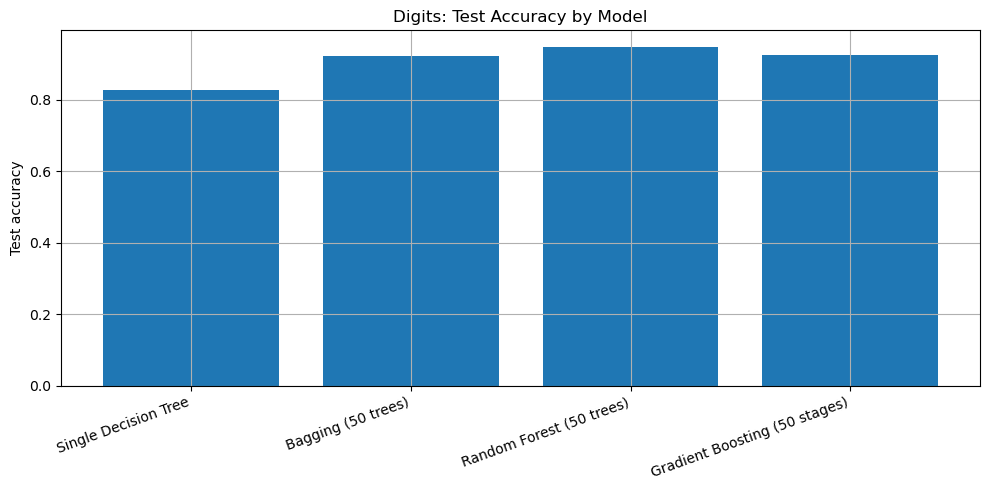

Highest test accuracy: Random Forest (50 trees)
Fastest training: Single Decision Tree
Use the table to judge the accuracy/time trade-off; the fastest model is not necessarily the most accurate.


In [21]:
plt.figure(figsize=(10, 5))
plt.bar(ensemble_results["Model"], ensemble_results["Test accuracy"])
plt.ylabel("Test accuracy")
plt.title("Digits: Test Accuracy by Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fastest_model = ensemble_results.loc[ensemble_results["Training time (seconds)"].idxmin(), "Model"]
best_test_model = ensemble_results.loc[ensemble_results["Test accuracy"].idxmax(), "Model"]
print("Highest test accuracy:", best_test_model)
print("Fastest training:", fastest_model)
print("Use the table to judge the accuracy/time trade-off; the fastest model is not necessarily the most accurate.")

### Effect of Number of Trees — Random Forest

Repeat Random Forest with `n_estimators` in `{10, 50, 100}` and plot validation accuracy.

,n_estimators,Train accuracy,Validation accuracy,Test accuracy,Training time (seconds)
0,10,0.9991,0.9278,0.9194,0.0498
1,50,1.0000,0.9778,0.9472,0.0995
2,100,1.0000,0.9750,0.9583,0.2162


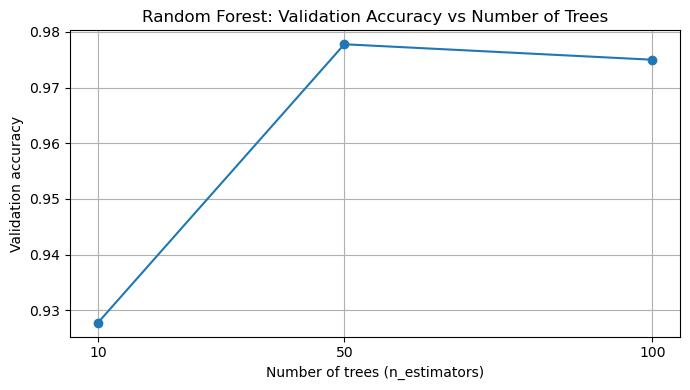

In [22]:
forest_rows = []
forest_models = {}
for n_trees in [10, 50, 100]:
    model = RandomForestClassifier(
        n_estimators=n_trees, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1
    )
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    forest_models[n_trees] = model
    forest_rows.append({
        "n_estimators": n_trees,
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Validation accuracy": accuracy_score(y_val, model.predict(X_val)),
        "Test accuracy": accuracy_score(y_test, model.predict(X_test)),
        "Training time (seconds)": elapsed
    })

forest_results = pd.DataFrame(forest_rows)
display(forest_results.style.format({
    "Train accuracy": "{:.4f}", "Validation accuracy": "{:.4f}",
    "Test accuracy": "{:.4f}", "Training time (seconds)": "{:.4f}"
}))
plt.figure(figsize=(7, 4))
plt.plot(forest_results["n_estimators"], forest_results["Validation accuracy"], marker="o")
plt.xticks([10, 50, 100])
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Validation accuracy")
plt.title("Random Forest: Validation Accuracy vs Number of Trees")
plt.tight_layout()
plt.show()

In [23]:
print("Ensemble observations:")
print("- Bagging fits bootstrap-resampled trees and aggregates their predictions, usually reducing variance versus one tree.")
print("- Random Forest adds feature subsampling at each split, decorrelating trees in addition to bootstrap sampling.")
print("- Gradient Boosting builds stages sequentially, each stage correcting errors of the current ensemble; it is not independent parallel bagging.")
print("- More trees can stabilize or improve validation accuracy, but gains are not guaranteed to be strictly monotonic.")
print("- Compare validation/test accuracy and training time in the tables above to choose a practical accuracy/time balance.")
best_forest_row = forest_results.loc[forest_results["Validation accuracy"].idxmax()]
print(f"Best RF validation accuracy in tested set: n_estimators={int(best_forest_row['n_estimators'])}, "
      f"accuracy={best_forest_row['Validation accuracy']:.4f}.")

Ensemble observations:
- Bagging fits bootstrap-resampled trees and aggregates their predictions, usually reducing variance versus one tree.
- Random Forest adds feature subsampling at each split, decorrelating trees in addition to bootstrap sampling.
- Gradient Boosting builds stages sequentially, each stage correcting errors of the current ensemble; it is not independent parallel bagging.
- More trees can stabilize or improve validation accuracy, but gains are not guaranteed to be strictly monotonic.
- Compare validation/test accuracy and training time in the tables above to choose a practical accuracy/time balance.
Best RF validation accuracy in tested set: n_estimators=50, accuracy=0.9778.


## Final Conclusion

Use the measured results below to summarize the experiments. These statements are generated from this notebook's run, rather than assuming a particular accuracy in advance.

In [24]:
# Compact, data-grounded final summary
best_cls_row = depth_results.loc[depth_results["Validation accuracy"].idxmax()]
best_reg_row = reg_depth_results.loc[reg_depth_results["Validation RMSE"].idxmin()]
best_ens_row = ensemble_results.loc[ensemble_results["Test accuracy"].idxmax()]
best_pruned_row = regression_comparison.loc[regression_comparison["Model"].str.startswith("Pruned tree")].iloc[0]

print("1) Classification tree depth and impurity")
print(f"   Entropy depth-4 validation accuracy = {impurity_comparison.loc[impurity_comparison['Criterion']=='Entropy', 'Validation accuracy'].iloc[0]:.4f}; "
      f"Gini depth-4 validation accuracy = {impurity_comparison.loc[impurity_comparison['Criterion']=='Gini', 'Validation accuracy'].iloc[0]:.4f}.")
print(f"   Best tested Gini depth by validation accuracy = {best_depth}; validation accuracy = {best_cls_row['Validation accuracy']:.4f}; "
      f"test accuracy = {best_classifier_test_accuracy:.4f}.")
print("   Deeper trees can fit more training detail; if training accuracy rises while validation accuracy stalls/falls, that suggests overfitting.")
print()
print("2) Regression and pruning")
print(f"   Best tested max_depth by validation RMSE = {best_reg_depth}; validation RMSE = {best_reg_row['Validation RMSE']:.3f}.")
print(f"   Best pruning alpha = {best_alpha:.6g}; pruned test RMSE = {best_pruned_row['Test RMSE']:.3f}, "
      f"leaves = {int(best_pruned_row['Leaf nodes'])}.")
print("   Cost-complexity pruning trades fit against tree size; whether it improves test RMSE is determined by the comparison table.")
print()
print("3) Ensembles")
print(f"   Highest test accuracy among the four primary models: {best_ens_row['Model']} "
      f"({best_ens_row['Test accuracy']:.4f}).")
print("   Bagging averages bootstrap trees; Random Forest also samples features; Gradient Boosting adds learners sequentially.")
print("   The best practical model should balance measured accuracy with training time and complexity.")

1) Classification tree depth and impurity
   Entropy depth-4 validation accuracy = 0.6500; Gini depth-4 validation accuracy = 0.5583.
   Best tested Gini depth by validation accuracy = 8; validation accuracy = 0.8389; test accuracy = 0.8278.
   Deeper trees can fit more training detail; if training accuracy rises while validation accuracy stalls/falls, that suggests overfitting.

2) Regression and pruning
   Best tested max_depth by validation RMSE = 2; validation RMSE = 58.781.
   Best pruning alpha = 93.8969; pruned test RMSE = 63.705, leaves = 8.
   Cost-complexity pruning trades fit against tree size; whether it improves test RMSE is determined by the comparison table.

3) Ensembles
   Highest test accuracy among the four primary models: Random Forest (50 trees) (0.9472).
   Bagging averages bootstrap trees; Random Forest also samples features; Gradient Boosting adds learners sequentially.
   The best practical model should balance measured accuracy with training time and complexit